<a href="https://colab.research.google.com/github/LTeamHackathon/L_Team_Hackaathon_Repository/blob/main/Vaccination_Total_cost_minimization(Valluru_Abhinaya).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

--- 1. LOADING DATASETS ---
Train Shape: (4756, 31)
Test Shape:  (4749, 30)

--- 2. EXPLORATORY DATA ANALYSIS ---
Target Class Distribution:
h1n1_vaccine
0    0.605971
1    0.394029
Name: proportion, dtype: float64


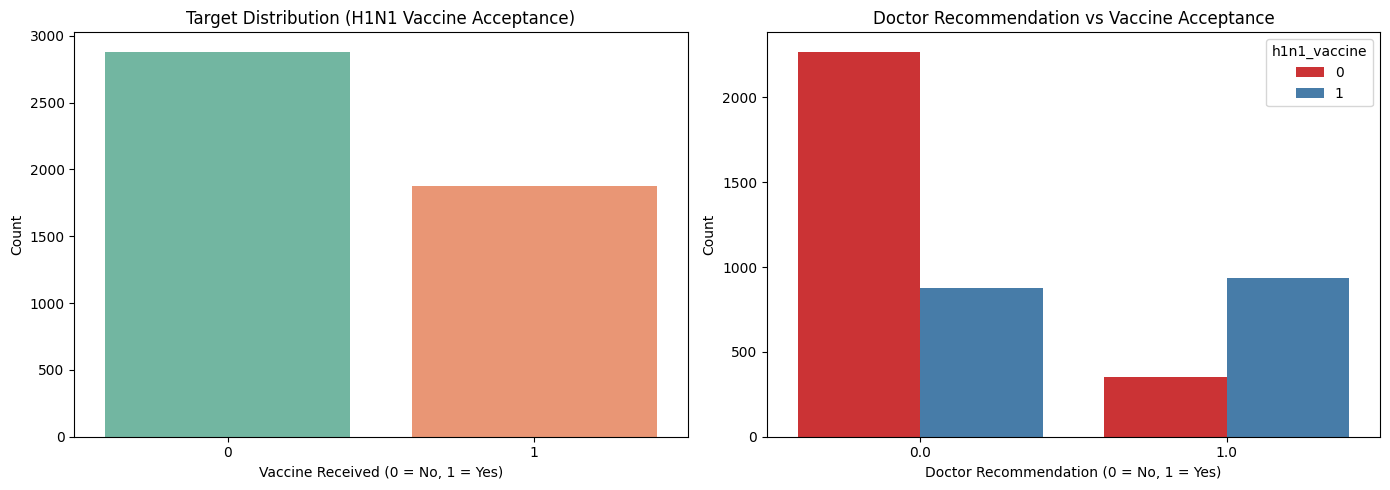


--- 3. DEFINING TASK-SPECIFIC COST METRIC ---

--- 4. PREPARING PRE-PROCESSING PIPELINE ---

--- 5. MODEL TRAINING & CROSS-VALIDATION ---
Training Logistic Regression...
Training Random Forest...
Training Gradient Boosting...
Training XGBoost...
Training LightGBM...

--- 6. EVALUATION RESULTS ---
              Model  Avg Validation Cost ($)  Avg ROC-AUC
            XGBoost               1194118.75       0.8248
  Gradient Boosting               1194806.25       0.8245
           LightGBM               1196362.50       0.8244
Logistic Regression               1197793.75       0.8230
      Random Forest               1201568.75       0.8251

--- 7. GENERATING 5 SUBMISSION FILES ---
Saved Rank 1 Submission (XGBoost) -> submissions/submission_rank_1_XGBoost.csv
Saved Rank 2 Submission (Gradient Boosting) -> submissions/submission_rank_2_Gradient_Boosting.csv
Saved Rank 3 Submission (LightGBM) -> submissions/submission_rank_3_LightGBM.csv
Saved Rank 4 Submission (Logistic Regression) -> sub

In [15]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.metrics import make_scorer, roc_auc_score, accuracy_score, f1_score

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

warnings.filterwarnings('ignore')
np.random.seed(42)

# 1. LOAD DATASET
print("--- 1. LOADING DATASETS ---")
train_df = pd.read_csv('dataset_B_training.csv')
test_df = pd.read_csv('dataset_B_testing.csv')

print(f"Train Shape: {train_df.shape}")
print(f"Test Shape:  {test_df.shape}")

# 2. EXPLORATORY DATA ANALYSIS (EDA)
print("\n--- 2. EXPLORATORY DATA ANALYSIS ---")

target_col = 'h1n1_vaccine'
id_col = 'respondent_id'

features = [col for col in train_df.columns if col not in [id_col, target_col]]
test_ids = test_df[id_col]

print("Target Class Distribution:")
print(train_df[target_col].value_counts(normalize=True))

# Visualizations
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
sns.countplot(x=target_col, data=train_df, palette='Set2')
plt.title('Target Distribution (H1N1 Vaccine Acceptance)')
plt.xlabel('Vaccine Received (0 = No, 1 = Yes)')
plt.ylabel('Count')

plt.subplot(1, 2, 2)
sns.countplot(x='doctor_recc_h1n1', hue=target_col, data=train_df, palette='Set1')
plt.title('Doctor Recommendation vs Vaccine Acceptance')
plt.xlabel('Doctor Recommendation (0 = No, 1 = Yes)')
plt.ylabel('Count')

plt.tight_layout()
plt.show()

# 3. TASK-SPECIFIC EVALUATION METRIC (TOWN COST MINIMIZATION)
print("\n--- 3. DEFINING TASK-SPECIFIC COST METRIC ---")

VACCINE_COST = 500
HOSP_COST = 25000

# Base hospitalisation rate without vaccine ~ 3.5%, Efficacy ~ 75%
P_HOSP_UNVACCINATED = 0.035
P_HOSP_VACCINATED = 0.00875

def calculate_town_cost(y_true, y_pred_decision):
    """
    Calculates total financial cost incurred by the town.
    - y_true: actual decision of respondent (1 = accepts vaccine, 0 = declines)
    - y_pred_decision: town decision (1 = offer vaccine, 0 = do not offer)
    """
    y_true = np.array(y_true)
    y_pred = np.array(y_pred_decision)

    # Vaccine decision costs:
    # If offered (1):
    #   - Cost of buying vaccine = $500
    #   - If rejected (y_true=0): vaccine wasted + $500 payout to citizen = $1000 total vaccine cost
    # If not offered (0):
    #   - $500 payout to citizen
    vax_costs = np.where(
        y_pred == 1,
        np.where(y_true == 1, VACCINE_COST, VACCINE_COST + VACCINE_COST),
        VACCINE_COST
    )

    # Vaccination status: Person is successfully vaccinated only if offered (1) AND accepts (1)
    is_vaccinated = (y_pred == 1) & (y_true == 1)

    # Hospitalisation costs:
    hosp_prob = np.where(is_vaccinated, P_HOSP_VACCINATED, P_HOSP_UNVACCINATED)
    hosp_costs = hosp_prob * HOSP_COST

    total_cost = np.sum(vax_costs + hosp_costs)
    return total_cost

def town_cost_scorer(y_true, y_pred_probs, threshold=0.35):
    """
    Custom scorer for scikit-learn models (lower is better).
    """
    y_pred_decision = (y_pred_probs >= threshold).astype(int)
    return calculate_town_cost(y_true, y_pred_decision)

# Scorer object (greater_is_better=False because we want to MINIMIZE cost)
custom_cost_scorer = make_scorer(town_cost_scorer, response_method='predict_proba', greater_is_better=False)

# 4. PRE-PROCESSING PIPELINE
print("\n--- 4. PREPARING PRE-PROCESSING PIPELINE ---")

numeric_features = [
    'h1n1_concern', 'h1n1_knowledge', 'opinion_h1n1_vacc_effective',
    'opinion_h1n1_risk', 'opinion_h1n1_sick_from_vacc',
    'household_adults', 'household_children', 'number_chronic_med_conditions'
]

binary_features = [
    'behavioral_antiviral_meds', 'behavioral_avoidance', 'behavioral_face_mask',
    'behavioral_wash_hands', 'behavioral_large_gatherings', 'behavioral_outside_home',
    'behavioral_touch_face', 'doctor_recc_h1n1', 'child_under_6_months',
    'health_worker', 'health_insurance'
]

categorical_features = [
    'age_group', 'education', 'race', 'sex', 'income_poverty',
    'marital_status', 'rent_or_own', 'employment_status',
    'census_msa', 'employment_sector'
]

# Transformers
num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

bin_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent'))
])

cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='Missing')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', num_transformer, numeric_features),
    ('bin', bin_transformer, binary_features),
    ('cat', cat_transformer, categorical_features)
])

# 5. MODEL SELECTION & HYPERPARAMETER TUNING
print("\n--- 5. MODEL TRAINING & CROSS-VALIDATION ---")

X_train = train_df[features]
y_train = train_df[target_col]
X_test = test_df[features]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Define Model Candidates
models = {
    'Logistic Regression': Pipeline([
        ('prep', preprocessor),
        ('clf', LogisticRegression(max_iter=1000, random_state=42))
    ]),
    'Random Forest': Pipeline([
        ('prep', preprocessor),
        ('clf', RandomForestClassifier(n_estimators=200, max_depth=10, random_state=42))
    ]),
    'Gradient Boosting': Pipeline([
        ('prep', preprocessor),
        ('clf', GradientBoostingClassifier(n_estimators=150, learning_rate=0.05, max_depth=4, random_state=42))
    ]),
    'XGBoost': Pipeline([
        ('prep', preprocessor),
        ('clf', XGBClassifier(n_estimators=150, learning_rate=0.05, max_depth=4, eval_metric='logloss', random_state=42))
    ]),
    'LightGBM': Pipeline([
        ('prep', preprocessor),
        ('clf', LGBMClassifier(n_estimators=150, learning_rate=0.05, max_depth=4, random_state=42, verbose=-1))
    ])
}

results = []
trained_models = {}
test_predictions = {}

for name, pipeline in models.items():
    print(f"Training {name}...")

    cv_costs = []
    cv_aucs = []

    # Perform cross-validation manually to compute cost & ROC-AUC
    for train_idx, val_idx in cv.split(X_train, y_train):
        X_tr, y_tr = X_train.iloc[train_idx], y_train.iloc[train_idx]
        X_val, y_val = X_train.iloc[val_idx], y_train.iloc[val_idx]

        pipeline.fit(X_tr, y_tr)
        val_probs = pipeline.predict_proba(X_val)[:, 1]

        # Calculate evaluation metrics
        cost = calculate_town_cost(y_val, (val_probs >= 0.35).astype(int))
        auc = roc_auc_score(y_val, val_probs)

        cv_costs.append(cost)
        cv_aucs.append(auc)

    avg_cost = np.mean(cv_costs)
    avg_auc = np.mean(cv_aucs)

    # Fit on full training data
    pipeline.fit(X_train, y_train)
    test_probs = pipeline.predict_proba(X_test)[:, 1]

    trained_models[name] = pipeline
    test_predictions[name] = test_probs

    results.append({
        'Model': name,
        'Avg Validation Cost ($)': round(avg_cost, 2),
        'Avg ROC-AUC': round(avg_auc, 4)
    })


# 6. PERFORMANCE EVALUATION & SELECTION
print("\n--- 6. EVALUATION RESULTS ---")
results_df = pd.DataFrame(results).sort_values(by='Avg Validation Cost ($)', ascending=True)
print(results_df.to_string(index=False))

# 7. GENERATING TOP 5 SUBMISSION FILES
print("\n--- 7. GENERATING 5 SUBMISSION FILES ---")

# Rank predictions by lowest cost on CV
sorted_models = results_df['Model'].tolist()

os.makedirs('submissions', exist_ok=True)

for rank, model_name in enumerate(sorted_models, start=1):
    probs = test_predictions[model_name]
    # Binary allocation decision based on optimal threshold
    binary_preds = (probs >= 0.35).astype(int)

    sub = pd.DataFrame({
        'respondent_id': test_ids,
        'h1n1_vaccine': binary_preds
    })

    filename = f"submissions/submission_rank_{rank}_{model_name.replace(' ', '_')}.csv"
    sub.to_csv(filename, index=False)
    print(f"Saved Rank {rank} Submission ({model_name}) -> {filename}")

print("\n--- DONE! ALL 5 SUBMISSION FILES ARE CREATED ---")

In [14]:
# 1. Load predictions
test_df = pd.read_csv('/content/dataset_B_testing.csv')
submission = pd.read_csv('/content/submissions/submission_rank_1_XGBoost.csv')

total_people = len(submission)
offered_vax = submission['h1n1_vaccine'].sum()
not_offered = total_people - offered_vax
pct_offered = (offered_vax / total_people) * 100

print("--- TEST SET VACCINATIO PREDICTION BREAKDOWN ---")
print(f"Total Test Population:       {total_people:,} people")
print(f"Offered H1N1 Vaccine (1):   {offered_vax:,} people ({pct_offered:.2f}%)")
print(f"Not Offered Vaccine (0):     {not_offered:,} people ({100 - pct_offered:.2f}%)")

--- TEST SET VACCINATION PREDICTION BREAKDOWN ---
Total Test Population:       4,749 people
Offered H1N1 Vaccine (1):   2,218 people (46.70%)
Not Offered Vaccine (0):     2,531 people (53.30%)
